<a href="https://colab.research.google.com/github/shashikawka/268452H-CS5998-Capstone-Project/blob/main/04_autoencoder_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Temporal Autoencoder for Anomaly Detection

This notebook implements a window based autoencoder for detecting
unusual behaviour in the MetroPT-3 railway APU sensor dataset.

The model uses windows of 60 observations with 15 sensor features.

I used the pre-failure data for training and the validation data to select the model settings and anomaly threshold. The evaluation data is kept separately to test how well the model performs.

###Step 1 : Data Preperation

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42) # Reproducibility

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPUs: []


In [5]:
#Load data

data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

# Load temporal windows
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training window:", X_train_windows.shape)
print("Validation window:", X_val_windows.shape)
print("Evaluation window:", X_eval_windows.shape)

print("\nData type:", X_train_windows.dtype)

Training window: (41938, 60, 15)
Validation window: (13749, 60, 15)
Evaluation window: (94307, 60, 15)

Data type: float32


In [6]:
#Verify the window data
print("Training shape valid:",
      X_train_windows.shape[1:] == (60, 15))

print("Validation shape valid:",
      X_val_windows.shape[1:] == (60, 15))

print("Evaluation shape valid:",
      X_eval_windows.shape[1:] == (60, 15))

print("\nFirst training window:", X_train_windows[0].shape)

print("Training values finite:",
      np.isfinite(X_train_windows).all())

print("Validation values finite:",
      np.isfinite(X_val_windows).all())

print("Evaluation values finite:",
      np.isfinite(X_eval_windows).all())

Training shape valid: True
Validation shape valid: True
Evaluation shape valid: True

First training window: (60, 15)
Training values finite: True
Validation values finite: True
Evaluation values finite: True


###Step 2 : Build the Autoencoder Architecture

In [7]:
#2.1 Cereate Auto Encoder
#simple dense autoencoder. It uses all observations within a window, but it does not explicitly model sequence order like an LSTM.
# Each window contains 60 observations and 15 features
window_size = X_train_windows.shape[1]
n_features = X_train_windows.shape[2]

input_dim = window_size * n_features

# Build the autoencoder
autoencoder = models.Sequential([
    layers.Input(shape=(window_size, n_features)),

    # Convert the window into a single vector
    layers.Flatten(),

    # Encoder
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),

    # Bottleneck
    layers.Dense(32, activation='relu'),

    # Decoder
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(input_dim, activation='linear'),

    # Restore the original window shape
    layers.Reshape((window_size, n_features))
])

# Configure the model
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse'
)

# Display the architecture
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 900)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       115,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 900)            │       116,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 60, 15)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,196 (985.14 KB)

 Trainable params: 252,196 (985.14 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
#2.2 Create a model
# Test the model using one training window
sample_window = np.asarray(X_train_windows[:1])

reconstructed_window = autoencoder.predict(
    sample_window,
    verbose=0
)

print("Original window shape:", sample_window.shape)
print("Reconstructed window shape:", reconstructed_window.shape)

Original window shape: (1, 60, 15)
Reconstructed window shape: (1, 60, 15)


##### OBSERVATION:
##### I created a dense autoencoder using the 60 observation windows.
##### Each window has 15 sensor features, giving 900 input values.
##### The encoder reduces these values to a 32-value bottleneck,
##### and the decoder tries to reconstruct the original window.
##### I used MSE to measure the reconstruction error.
##### The model has not been trained yet.

###Step 3 : Train the Autoencoder

In [11]:
#3.1 train the model
# Stop training if validation loss does not improve for 5 epochs
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the autoencoder
history = autoencoder.fit(
    X_train_windows,
    X_train_windows,
    validation_data=(X_val_windows, X_val_windows),
    epochs=30,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAutoencoder training completed.")
print("Epochs completed:", len(history.history['loss']))
print("Best validation loss:", min(history.history['val_loss']))

Epoch 1/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0260 - val_loss: 0.0803
Epoch 2/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0255 - val_loss: 0.0792
Epoch 3/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0248 - val_loss: 0.0791
Epoch 4/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 0.0244 - val_loss: 0.0778
Epoch 5/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0239 - val_loss: 0.0776
Epoch 6/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0235 - val_loss: 0.0778
Epoch 7/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0231 - val_loss: 0.0769
Epoch 8/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0227 - val_loss: 0.0771
Epoch 9/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0224 - val_loss: 0.0766
Epoch 10/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0220 - val_loss: 0.0763
Epoch 11/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0218 - val_loss: 0.0748
Epoch 12/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 

##### OBSERVATIONS:
##### I trained the autoencoder using the training windows and used the validation windows to monitor its reconstruction loss.
##### I set the maximum training epochs to 30 and used early stopping to stop training if the validation loss did not improve.
##### After training, I will compare the training and validation loss curves to check how well the model learned.

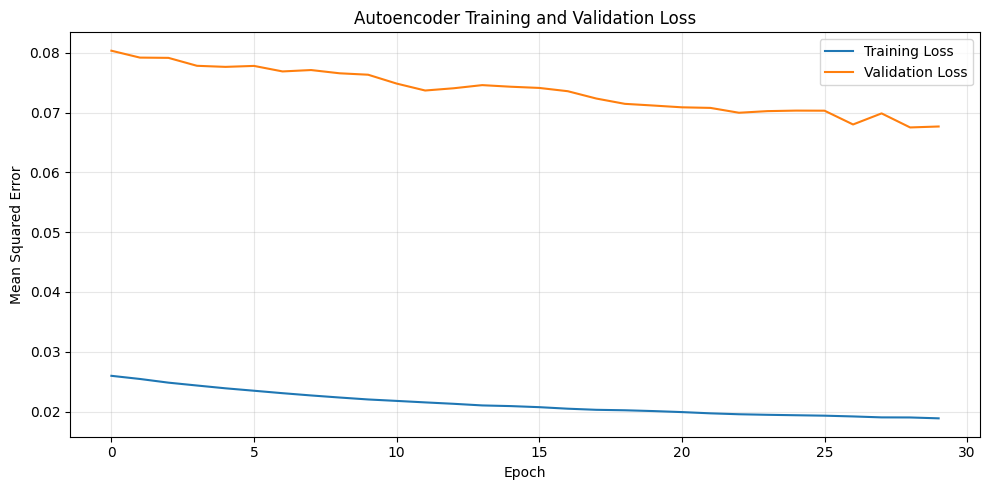

<Figure size 640x480 with 0 Axes>

In [13]:
#3.2 Visualize training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder_Training_And_Valisation_Loss.png',
    dpi=300,
    bbox_inches='tight'
)

##### OBESERVATIONS:
##### The autoencoder completed all 30 training epochs. The training loss decreased from 0.0260 to 0.0189.
##### The validation loss also decreased, with the lowest value of 0.0675 recorded at epoch 29.
##### The validation loss remained higher than the training loss.
##### This may be due to differences in sensor behaviour between the training and validation periods.
##### Further evaluation is needed to check anomaly detection performance.